TypeError: unsupported operand type(s) for /: 'str' and 'str'

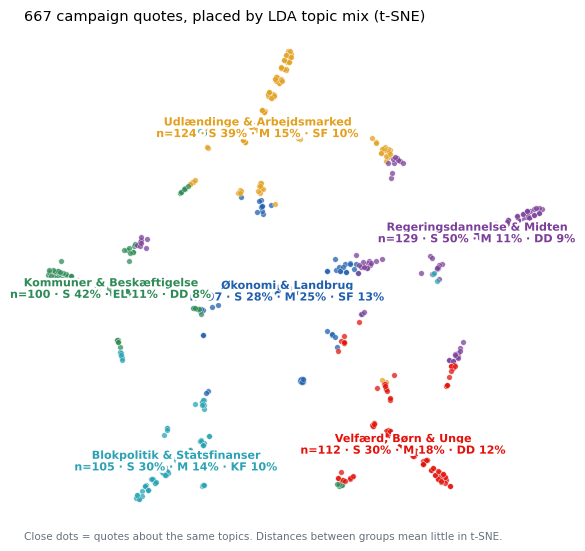

In [4]:
# --- t-SNE of the campaign quotes (LDA), same as the atlas – static version ---
import ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.manifold import TSNE


# 1. Same data, stopwords and LDA as tfidf.ipynb, so the topics are the atlas topics
df = pd.read_csv("/Users/salmahirsi/Documents/GitHub/Politics-Network/data/tokenized_citater.csv")
df["tokens"] = df["tokens"].apply(lambda v: ast.literal_eval(v) if isinstance(v, str) else [])
df = df.dropna(subset=["parti"])
df = df[df["tokens"].map(len) > 0]
ord_pr_parti = df.groupby("parti")["tokens"].apply(lambda l: sum(map(len, l)))
valid_parties = ord_pr_parti[ord_pr_parti >= 100].index
custom_stopwords = ["sige", "mene", "udtale", "spørge", "svare", "fortælle", "kalde", "pege",
    "helt", "rigtig", "faktisk", "selvfølgelig", "god", "godt", "stor", "stort", "hel", "få", "gå", "tage", "se", "give",
    "komme", "blive", "gøre", "kunne", "ville", "skulle", "måtte", "når", "hvor", "hvordan", "fordi", "også", "bare",
    "lidt", "meget", "mange", "flere", "ny", "nyt", "nye", "dansk", "danmark", "parti", "partier", "politik", "politisk",
    "valgkamp", "valg", "folketingsvalg", "folk", "ting", "sag", "måde", "dag", "år", "gang", "tid", "del", "spørgsmål",
    "mette", "frederiksen", "lars", "løkke", "rasmussen", "jakob", "ellemann", "jensen", "søren", "pape", "poulsen",
    "pia", "olsen", "dyhr", "inger", "støjberg", "alex", "vanopslagh", "sofie", "carsten", "nielsen", "mai",
    "villadsen", "morten", "messerschmidt", "pernille", "vermund", "franciska", "rosenkilde"]
df_lda = df[df["parti"].isin(valid_parties)].copy()
df_lda = df_lda[df_lda["tokens"].map(len) >= 5].reset_index(drop=True)
count_vec = CountVectorizer(min_df=5, max_df=0.50, stop_words=custom_stopwords)
dtm = count_vec.fit_transform(df_lda["tokens"].apply(" ".join))
lda = LatentDirichletAllocation(n_components=6, random_state=42, max_iter=25)
theta = lda.fit_transform(dtm)
theta = theta / theta.sum(1, keepdims=True)
df_lda["emne"] = theta.argmax(1)

EMNER = ["Økonomi & Landbrug", "Udlændinge & Arbejdsmarked", "Kommuner & Beskæftigelse",
         "Regeringsdannelse & Midten", "Velfærd, Børn & Unge", "Blokpolitik & Statsfinanser"]
EMNE_FARVER = ["#1F5FAD", "#E3A01F", "#2E8B57", "#7B3F98", "#E3120B", "#2BA3B4"]          # atlas colours

# 2. t-SNE exactly as in the atlas: Hellinger distance = Euclidean distance on sqrt(theta)
xy = TSNE(n_components=2, perplexity=min(30, (len(df_lda) - 1) / 3), metric="euclidean", init="pca",
          learning_rate="auto", random_state=42).fit_transform(np.sqrt(theta))
df_lda["x"], df_lda["y"] = xy[:, 0], xy[:, 1]

# 3. Draw: topic name, n and the 3 parties that say most, written on each topic's main group
fig, ax = plt.subplots(figsize=(7, 6.4))
for i, f in enumerate(EMNE_FARVER):
    d = df_lda[df_lda["emne"] == i]
    ax.scatter(d["x"], d["y"], s=16, color=f, alpha=0.75, linewidths=0.3, edgecolors="white")
    kerne = d.loc[((d[["x", "y"]] - d[["x", "y"]].median()) ** 2).sum(1).nsmallest(max(5, len(d) // 3)).index]
    top = d["parti"].value_counts(normalize=True).head(3)
    ax.text(kerne["x"].median(), kerne["y"].median(),
            f"{EMNER[i]}\nn={len(d)} · " + " · ".join(f"{p} {v:.0%}" for p, v in top.items()),
            ha="center", va="center", fontsize=8, fontweight="bold", color=f,
            path_effects=[pe.withStroke(linewidth=3.5, foreground="white")])
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"{len(df_lda)} campaign quotes, placed by LDA topic mix (t-SNE)", fontsize=10.5, loc="left")
ax.text(0, -0.02, "Close dots = quotes about the same topics. Distances between groups mean little in t-SNE.",
        transform=ax.transAxes, fontsize=7.5, color="#66717d", va="top")
fig.savefig(project_root / "docs" / "assets" / "figures" / "fig_citater_tsne.png", dpi=300, bbox_inches="tight")
plt.show()